# Student Performance Prediction Using Machine Learning

## Major Project – Data Science

This notebook performs data loading, preprocessing, exploratory data analysis (EDA), model training, evaluation, and student performance prediction.

## 1. Import Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Load the Dataset

In [3]:
# The notebook is inside notebooks/, so ../data points to the project data folder.
DATA_PATH = '../data/student_performance.csv'
df = pd.read_csv(DATA_PATH)

df.head()

,student_id,gender,age,study_hours,attendance,previous_score,assignment_score,midterm_score,extracurricular,internet_access,sleep_hours,final_score
0,STU0001,Male,21,4.2,79.4,47.0,70.6,30.0,No,Yes,4.5,55.3
1,STU0002,Female,16,4.8,98.0,92.7,91.0,51.8,Yes,Yes,7.2,75.0
2,STU0003,Male,16,6.7,87.6,68.6,75.7,62.7,No,Yes,9.1,84.5
3,STU0004,Male,16,3.0,79.0,75.4,79.1,42.7,Yes,Yes,6.6,61.2
4,STU0005,Male,20,5.2,89.0,71.5,70.4,49.3,No,Yes,6.8,68.0


## 3. Dataset Overview

In [4]:
print('Dataset Shape:', df.shape)
print('\nColumn Names:')
print(df.columns.tolist())

df.info()

Dataset Shape: (1000, 12)

Column Names:
['student_id', 'gender', 'age', 'study_hours', 'attendance', 'previous_score', 'assignment_score', 'midterm_score', 'extracurricular', 'internet_access', 'sleep_hours', 'final_score']
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        1000 non-null   str    
 1   gender            1000 non-null   str    
 2   age               1000 non-null   int64  
 3   study_hours       1000 non-null   float64
 4   attendance        1000 non-null   float64
 5   previous_score    1000 non-null   float64
 6   assignment_score  1000 non-null   float64
 7   midterm_score     1000 non-null   float64
 8   extracurricular   1000 non-null   str    
 9   internet_access   1000 non-null   str    
 10  sleep_hours       1000 non-null   float64
 11  final_score       1000 non-null   float64
dtypes: float64(7), in

## 4. Statistical Summary

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,1000,1000,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,1000,2,Female,510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1000.0,NaN,NaN,NaN,18.473,1.740776,16.0,17.0,18.0,20.0,21.0
study_hours,1000.0,NaN,NaN,NaN,4.6312,1.740786,1.0,3.4,4.6,5.8,10.0
attendance,1000.0,NaN,NaN,NaN,81.9533,9.497371,51.8,75.6,82.0,88.5,100.0
previous_score,1000.0,NaN,NaN,NaN,71.6658,12.10028,36.1,63.2,71.8,80.025,98.0
assignment_score,1000.0,NaN,NaN,NaN,74.0665,9.628868,46.6,67.9,74.05,80.6,100.0
midterm_score,1000.0,NaN,NaN,NaN,47.421,11.456117,30.0,38.25,47.15,55.4,86.6
extracurricular,1000,2,No,526,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internet_access,1000,2,Yes,894,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Check Missing Values and Duplicates

In [6]:
print('Missing Values:')
display(df.isnull().sum())

print('Duplicate Rows:', df.duplicated().sum())

Missing Values:


student_id          0
gender              0
age                 0
study_hours         0
attendance          0
previous_score      0
assignment_score    0
midterm_score       0
extracurricular     0
internet_access     0
sleep_hours         0
final_score         0
dtype: int64

Duplicate Rows: 0


## 6. Data Preprocessing

In [7]:
# Remove duplicate records if any are present.
df = df.drop_duplicates().copy()

# The target variable is final_score.
target = 'final_score'

# Student ID is an identifier and should not be used as a predictive feature.
X = df.drop(columns=[target, 'student_id'])
y = df[target]

categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numeric_features = X.select_dtypes(exclude=['object']).columns.tolist()

print('Numeric Features:', numeric_features)
print('Categorical Features:', categorical_features)

Numeric Features: ['age', 'study_hours', 'attendance', 'previous_score', 'assignment_score', 'midterm_score', 'sleep_hours']
Categorical Features: ['gender', 'extracurricular', 'internet_access']


## 7. Exploratory Data Analysis (EDA)

### 7.1 Distribution of Final Scores

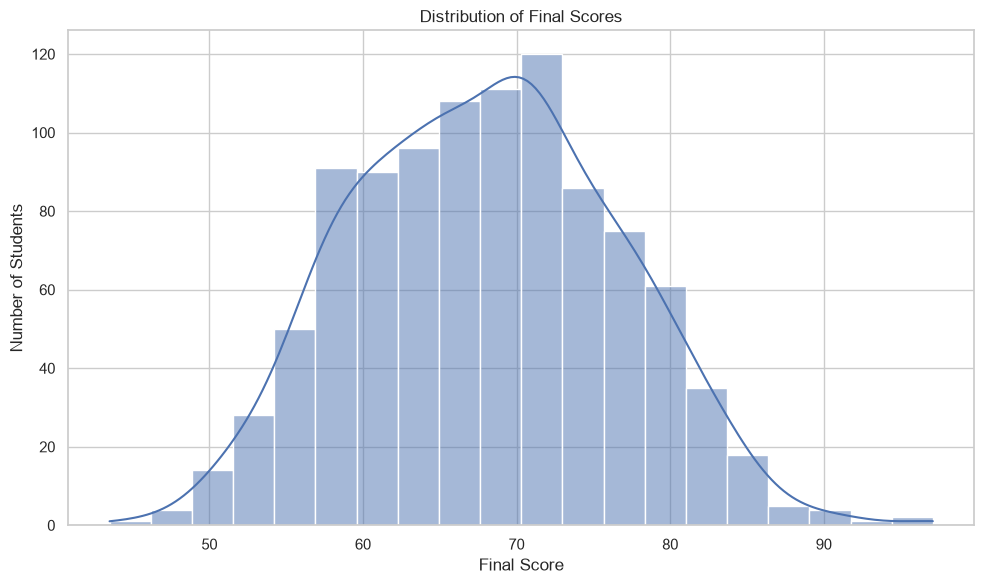

In [8]:
plt.figure(figsize=(10, 6))
sns.histplot(df['final_score'], bins=20, kde=True)
plt.title('Distribution of Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()

### 7.2 Study Hours vs Final Score

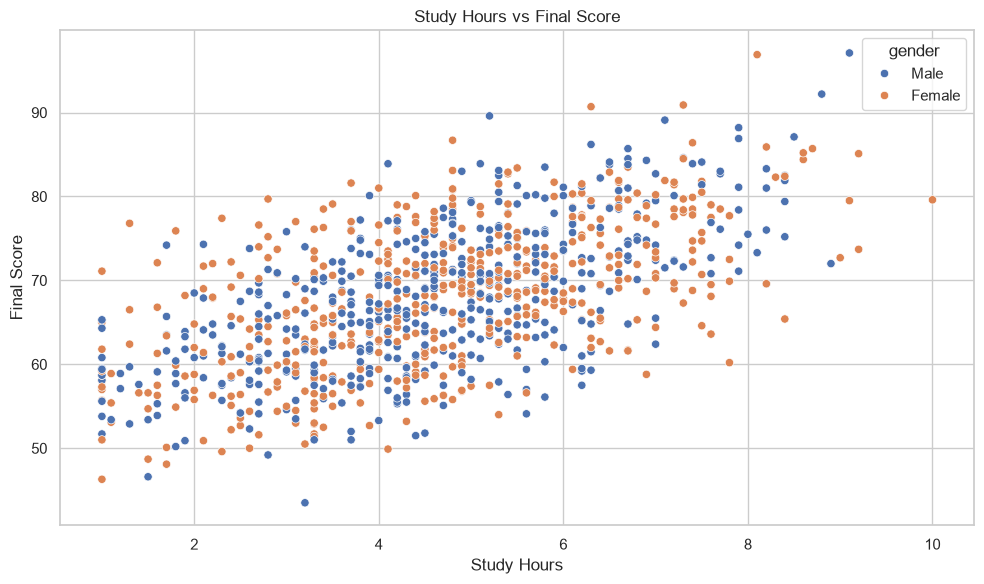

In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='study_hours', y='final_score', hue='gender')
plt.title('Study Hours vs Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.tight_layout()
plt.show()

### 7.3 Attendance vs Final Score

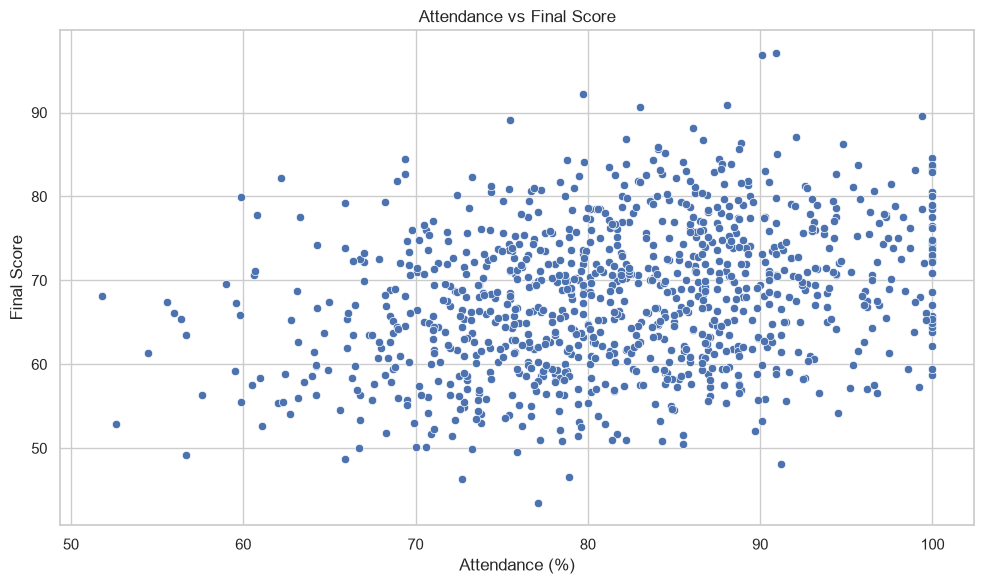

In [10]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='attendance', y='final_score')
plt.title('Attendance vs Final Score')
plt.xlabel('Attendance (%)')
plt.ylabel('Final Score')
plt.tight_layout()
plt.show()

### 7.4 Previous Score vs Final Score

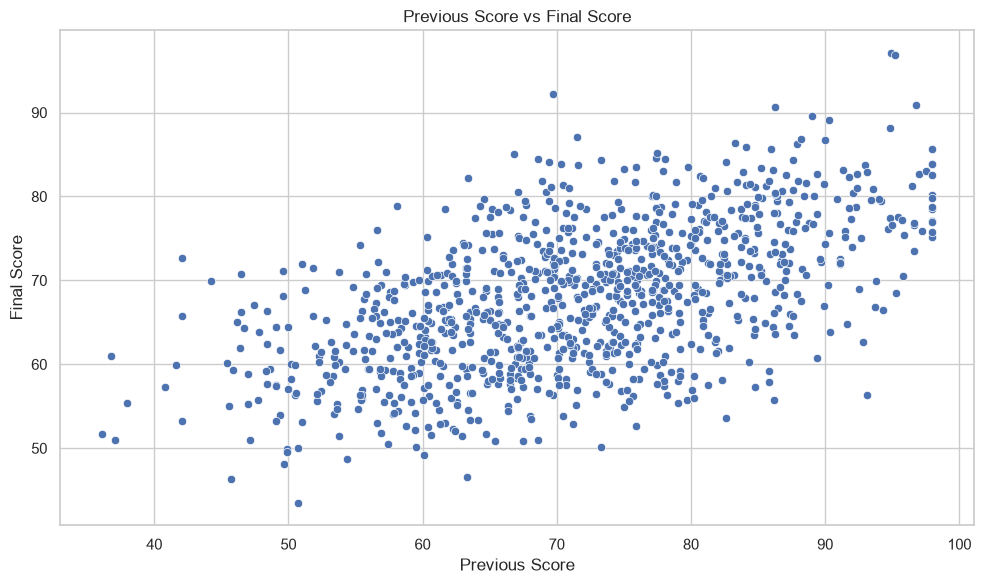

In [11]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='previous_score', y='final_score')
plt.title('Previous Score vs Final Score')
plt.xlabel('Previous Score')
plt.ylabel('Final Score')
plt.tight_layout()
plt.show()

### 7.5 Correlation Heatmap

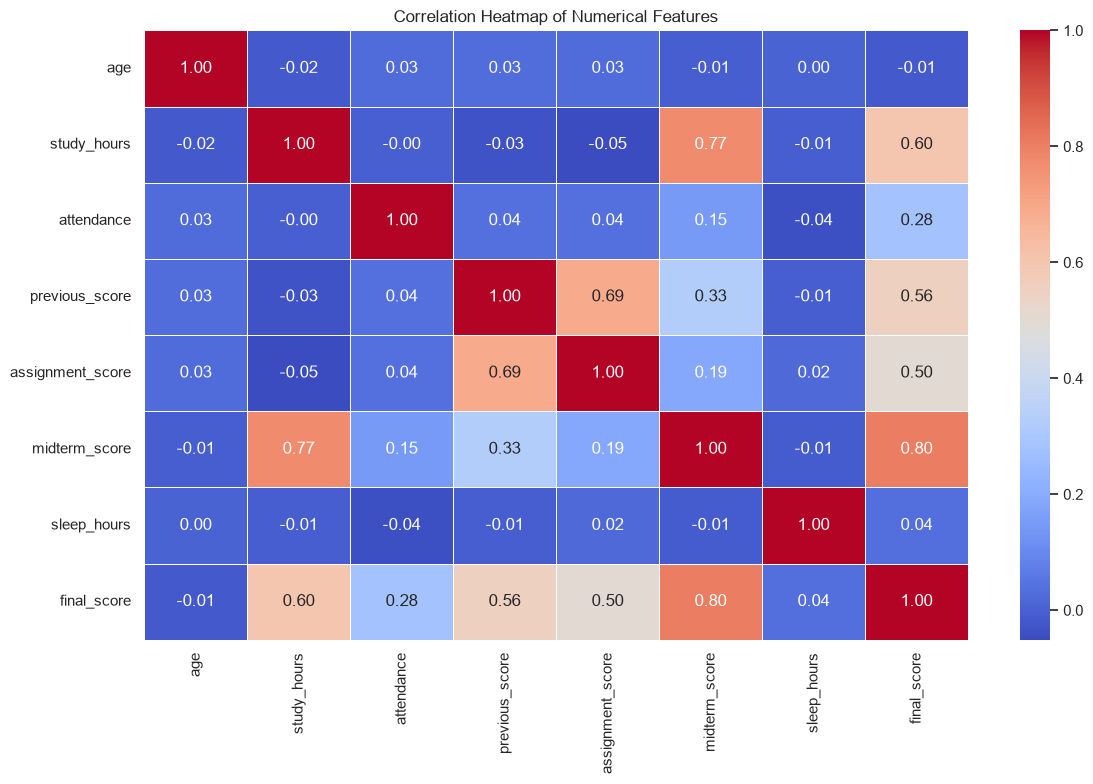

In [12]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

## 8. Prepare Data for Machine Learning

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print('Training Samples:', X_train.shape[0])
print('Testing Samples:', X_test.shape[0])

Training Samples: 800
Testing Samples: 200


## 9. Train Linear Regression Model

In [14]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)
print('Linear Regression model trained successfully.')

Linear Regression model trained successfully.


## 10. Model Evaluation

In [15]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE  : {mae:.2f}')
print(f'MSE  : {mse:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'R²   : {r2:.4f}')

MAE  : 2.42
MSE  : 9.54
RMSE : 3.09
R²   : 0.8681


## 11. Actual vs Predicted Scores

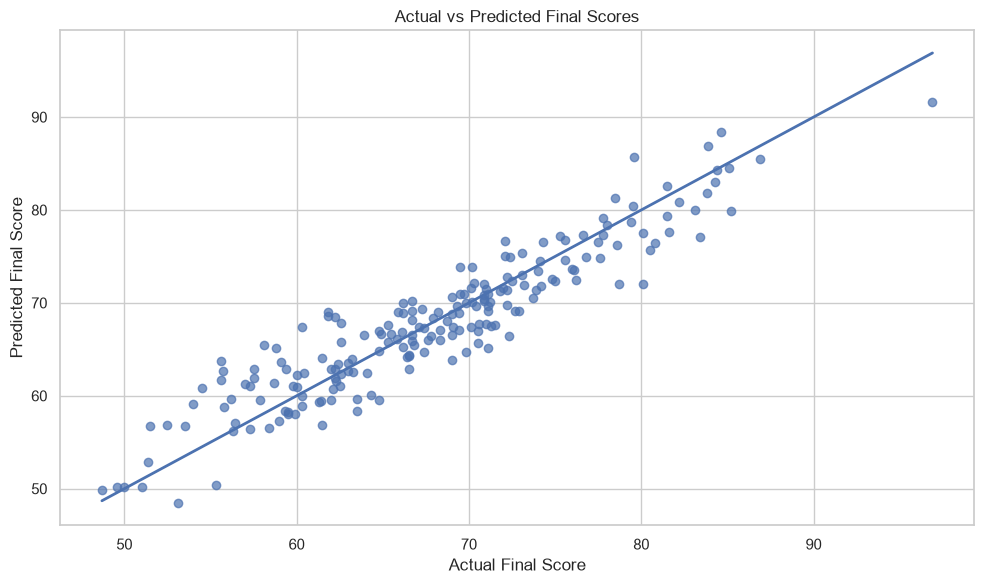

In [16]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linewidth=2)
plt.title('Actual vs Predicted Final Scores')
plt.xlabel('Actual Final Score')
plt.ylabel('Predicted Final Score')
plt.tight_layout()
plt.show()

## 12. Prediction for a New Student

In [18]:
new_student = pd.DataFrame([{
    'gender': 'Female',
    'age': 18,
    'study_hours': 5.0,
    'attendance': 90.0,
    'previous_score': 78.0,
    'assignment_score': 85.0,
    'midterm_score': 82.0,
    'extracurricular': 'Yes',
    'internet_access': 'Yes',
    'sleep_hours': 7.0
}])

predicted_score = model.predict(new_student)[0]
print(f'Predicted Final Score: {predicted_score:.2f}')

Predicted Final Score: 84.92


## 13. Conclusion

The analysis identifies relationships between academic and lifestyle factors and student final performance. A Linear Regression model is trained to predict final scores for new student records. The evaluation metrics above should be reported in the final Major Project documentation.